# Tahap 1: Eksplorasi Awal (EDA) & Pembersihan Data

**Proyek:** Biomass & Waste-to-Energy Feedstock Finder (Fokus: *Co-Firing* PLTU & Gasifikasi Biomassa)  
**Posisi dalam Alur Kerja:** Notebook ke-1 dari 3 (Tahap 1: *Data Preparation & Cleaning*)  
**Prasyarat Notebook:** Tidak ada (menggunakan data mentah baca-saja di `raw_data/`).

## Tujuan Notebook
1. Membersihkan dataset kimia dan nilai kalor **Mendeley (315 sampel)** dari duplikasi fitur-target, anomali neraca massa ekstrem, serta menormalisasi 14 baris basis DAF ke *dry basis* agar siap menjadi data latih dan uji model ML.
2. Menyeleksi **10 profil biomassa pertanian, perkebunan, dan kayu (`FS01`-`FS10`)** dari database **Phyllis2**, melengkapi data *proximate* `FS01` yang kosong secara teraudit, menstandarisasi satuan klorin dan logam alkali basis kering, serta menautkan parameter lapangan dari **ref_rpr_parameters.csv**.
3. Membersihkan seluruh data produksi pertanian dan perkebunan tingkat kabupaten/kota dari **BDSP Kementan (`152` file CSV, `padi`, `jagung`, `kelapa_sawit`, `tebu`)** dan data produksi kayu dari **BPS RI (`8` file CSV, level pulau & nasional)**, menyelaraskan 541 kode kab/kota mentah menjadi **514 kab/kota resmi (38 provinsi)**, mengaudit anomali dan kekosongan pelaporan tanpa imputasi, serta menerapkan **Strategi Dual-View** (`is_anchor_2022` dan `is_latest_complete_year`) untuk komparasi lintas komoditas.

## Daftar Input (*Read-Only*)
- `raw_data/05_biomassa_komplementer/biomass_hhv_315_samples.csv`
- `raw_data/05_biomassa_komplementer/phyllis2_all_18_wide-v3.csv`
- `raw_data/05_biomassa_komplementer/ref_rpr_parameters.csv`
- `raw_data/01_bdsp_kementan/{padi,jagung,kelapa_sawit,tebu}/kabkota/` (152 file CSV, 38 provinsi x 4 komoditas)
- `raw_data/02_bps/bps_ri/1973_kayu_hph_pulau/` & `raw_data/02_bps/bps_ri/2512_kayu_jenis_pohon/` (8 file CSV)

## Daftar Output yang Dihasilkan
- `data/processed/mendeley_clean.csv` & `data/processed/mendeley_cleaning_log.csv`
- `data/processed/phyllis2_10_clean.csv`
- `data/processed/bdsp_kabkota_clean.csv` & `data/processed/bdsp_dim_kabkota.csv`
- `data/processed/bps_kayu_pulau_clean.csv`, `data/processed/bps_kayu_nasional_clean.csv`, & `data/processed/bps_kayu_nasional_reference.csv`
- `data/processed/production_audit_log.csv`
- Grafik EDA di `outputs/figures/` (`01_eda_mendeley_overview.png` dan `01_eda_production_dualview.png`)

## 1. Persiapan Lingkungan & Pengaturan Direktori

**Langkah yang dikerjakan:** Mengimpor pustaka pengolahan data dan visualisasi, mendeteksi akar folder proyek (`projectkb`) secara otomatis, dan memastikan seluruh direktori keluaran tersedia.  
**Alasan teknis:** Deteksi akar folder mencegah kegagalan path saat notebook dijalankan dari folder `notebooks/` maupun dari folder utama proyek oleh anggota tim yang berbeda.

In [1]:
from pathlib import Path
import glob
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

# Deteksi root proyek agar notebook aman dijalankan dari root maupun dari subfolder notebooks/
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
assert (PROJECT_ROOT / "raw_data").exists(), f"Folder raw_data tidak ditemukan di {PROJECT_ROOT}"

RAW_COMP_DIR = PROJECT_ROOT / "raw_data" / "05_biomassa_komplementer"
RAW_BDSP_DIR = PROJECT_ROOT / "raw_data" / "01_bdsp_kementan"
RAW_BPS_DIR = PROJECT_ROOT / "raw_data" / "02_bps" / "bps_ri"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"RAW_BDSP_DIR : {RAW_BDSP_DIR}")
print(f"RAW_BPS_DIR  : {RAW_BPS_DIR}")
print(f"PROCESSED_DIR: {PROCESSED_DIR}")
print(f"FIGURES_DIR  : {FIGURES_DIR}")

PROJECT_ROOT : D:\UPN VY\Semester 5\BI\Tugas\projectkb
RAW_BDSP_DIR : D:\UPN VY\Semester 5\BI\Tugas\projectkb\raw_data\01_bdsp_kementan
RAW_BPS_DIR  : D:\UPN VY\Semester 5\BI\Tugas\projectkb\raw_data\02_bps\bps_ri
PROCESSED_DIR: D:\UPN VY\Semester 5\BI\Tugas\projectkb\data\processed
FIGURES_DIR  : D:\UPN VY\Semester 5\BI\Tugas\projectkb\outputs\figures


## 2. Pembersihan & EDA Dataset Mendeley (`biomass_hhv_315_samples.csv`)

### 2.1 Standarisasi Kolom, Penghapusan Duplikat, & Audit Neraca Massa
**Langkah yang dikerjakan:** Membaca 315 sampel mentah, menyeragamkan nama kolom fitur kimia dan target `hhv_db`, membuang duplikat identik pada fitur + target, lalu memeriksa neraca massa basis kering dan kewajaran nilai HHV.  
**Alasan teknis & acuan Project Brief:**
1. Menghapus duplikat identik (16 baris, misalnya `Rice huskb` yang identik dengan `Rice husk`) mencegah kebocoran data (*data leakage*) antara *training set* dan *testing set* pada Notebook 02.
2. Beberapa literatur mencatat *Volatile Matter* + *Fixed Carbon* dalam basis *dry ash-free* lalu ditambah abu sehingga total melebihi 100%, atau memiliki ketimpangan besar pada total unsur. Data dengan kesalahan parah tersebut perlu dikeluarkan agar model regresi mempelajari hubungan fisika-kimia yang valid.

**Aturan dan rumus yang diterapkan:**
- $\text{prox\_sum} = \text{ash\_db} + \text{vm\_db} + \text{fc\_db}$
- $\text{ult\_sum} = \text{c\_db} + \text{h\_db} + \text{o\_db} + \text{n\_db} + \text{s\_db} + \text{ash\_db}$
- **Filter keras (dikeluarkan):** `prox_sum` di luar `90%-105%`, `ult_sum` di luar `90%-105%`, atau `hhv_db` di luar `10-28 MJ/kg`. Seluruh 6 kategori biomassa (termasuk `manure`) tetap dipertahankan selama lolos filter keras.
- **Normalisasi DAF ke *Dry Basis*:** baris bersih dengan `C+H+O+N+S = 100% (±0,5%)` dan `ult_sum > 102%` (14 baris yang dicatat pada basis *dry ash-free*) dikalikan faktor `(100 - ash_db) / 100` agar seluruh komposisi unsur seragam dalam basis kering (`is_daf_normalized = True`).
- **Penanda lunak (`mass_balance_warning`):** bernilai `True` jika `prox_sum` atau `ult_sum` setelah normalisasi berada di luar `98%-102%` tetapi masih dalam rentang aman `90%-105%`.

In [2]:
mendeley_raw_path = RAW_COMP_DIR / "biomass_hhv_315_samples.csv"
df_m_raw = pd.read_csv(mendeley_raw_path)

print(f"Dimensi awal Mendeley: {df_m_raw.shape}")
print(f"Total sel NaN pada dataset mentah: {int(df_m_raw.isna().sum().sum())}")

# Seragamkan nama kolom kimia agar konsisten dengan fitur Phyllis2 dan pipeline ML
rename_mendeley = {
    "ash_wt_pct_db": "ash_db",
    "vm_wt_pct_db": "vm_db",
    "fc_wt_pct_db": "fc_db",
    "c_wt_pct_db": "c_db",
    "h_wt_pct_db": "h_db",
    "o_wt_pct_db": "o_db",
    "n_wt_pct_db": "n_db",
    "s_wt_pct_db": "s_db",
    "hhv_mj_kg": "hhv_db",
}
keep_cols = [
    "no", "material", "feedstock_category",
    "ash_db", "vm_db", "fc_db",
    "c_db", "h_db", "o_db", "n_db", "s_db", "hhv_db",
    "reference_code", "is_n_imputed_bold_brown", "is_s_imputed_bold_brown",
]
df_m = df_m_raw.rename(columns=rename_mendeley)[keep_cols].copy()

# Tahap A: Hapus duplikat identik pada gabungan 8 fitur kimia + target HHV
feature_target_cols = ["ash_db", "vm_db", "fc_db", "c_db", "h_db", "o_db", "n_db", "s_db", "hhv_db"]
dup_mask = df_m.duplicated(subset=feature_target_cols, keep="first")

log_dups = df_m.loc[dup_mask].copy()
log_dups["prox_sum"] = log_dups["ash_db"] + log_dups["vm_db"] + log_dups["fc_db"]
log_dups["ult_sum"] = (
    log_dups["c_db"] + log_dups["h_db"] + log_dups["o_db"]
    + log_dups["n_db"] + log_dups["s_db"] + log_dups["ash_db"]
)
log_dups["removal_stage"] = "deduplication"
log_dups["removal_reason"] = "exact_duplicate_features_and_hhv"

df_m_dedup = df_m.loc[~dup_mask].copy()

# Tahap B: Hitung neraca massa basis kering dan terapkan penyaringan anomali ekstrem
df_m_dedup["prox_sum"] = df_m_dedup["ash_db"] + df_m_dedup["vm_db"] + df_m_dedup["fc_db"]
df_m_dedup["ult_sum"] = (
    df_m_dedup["c_db"] + df_m_dedup["h_db"] + df_m_dedup["o_db"]
    + df_m_dedup["n_db"] + df_m_dedup["s_db"] + df_m_dedup["ash_db"]
)

bad_prox = (df_m_dedup["prox_sum"] < 90.0) | (df_m_dedup["prox_sum"] > 105.0)
bad_ult = (df_m_dedup["ult_sum"] < 90.0) | (df_m_dedup["ult_sum"] > 105.0)
bad_hhv = (df_m_dedup["hhv_db"] < 10.0) | (df_m_dedup["hhv_db"] > 28.0)
extreme_mask = bad_prox | bad_ult | bad_hhv

def format_extreme_reason(idx: int) -> str:
    reasons = []
    if bad_prox.loc[idx]:
        reasons.append(f"prox_sum_out_of_90_105 ({df_m_dedup.loc[idx, 'prox_sum']:.2f}%)")
    if bad_ult.loc[idx]:
        reasons.append(f"ult_sum_out_of_90_105 ({df_m_dedup.loc[idx, 'ult_sum']:.2f}%)")
    if bad_hhv.loc[idx]:
        reasons.append(f"hhv_out_of_10_28 ({df_m_dedup.loc[idx, 'hhv_db']:.2f} MJ/kg)")
    return "; ".join(reasons)

log_extreme = df_m_dedup.loc[extreme_mask].copy()
log_extreme["removal_stage"] = "extreme_anomaly_filter"
log_extreme["removal_reason"] = [format_extreme_reason(i) for i in log_extreme.index]

# Dataset bersih akhir: normalisasi basis DAF -> Dry Basis (14 baris di mana C+H+O+N+S ~= 100% dan ult_sum > 102%)
df_m_clean = df_m_dedup.loc[~extreme_mask].copy()
chons_sum = (
    df_m_clean["c_db"] + df_m_clean["h_db"] + df_m_clean["o_db"]
    + df_m_clean["n_db"] + df_m_clean["s_db"]
)
daf_mask = (chons_sum.sub(100.0).abs() <= 0.5) & (df_m_clean["ult_sum"] > 102.0)
df_m_clean["is_daf_normalized"] = daf_mask
for col in ["c_db", "h_db", "o_db", "n_db", "s_db"]:
    df_m_clean.loc[daf_mask, col] = (
        df_m_clean.loc[daf_mask, col] * (100.0 - df_m_clean.loc[daf_mask, "ash_db"]) / 100.0
    ).round(4)

df_m_clean["ult_sum"] = (
    df_m_clean["c_db"] + df_m_clean["h_db"] + df_m_clean["o_db"]
    + df_m_clean["n_db"] + df_m_clean["s_db"] + df_m_clean["ash_db"]
)

# Penanda deviasi lunak (98%-102%) setelah normalisasi DAF
df_m_clean["mass_balance_warning"] = (
    (df_m_clean["prox_sum"] < 98.0) | (df_m_clean["prox_sum"] > 102.0)
    | (df_m_clean["ult_sum"] < 98.0) | (df_m_clean["ult_sum"] > 102.0)
)

df_m_log = pd.concat([log_dups, log_extreme], ignore_index=True)

# Simpan ke data/processed/
df_m_clean.to_csv(PROCESSED_DIR / "mendeley_clean.csv", index=False)
df_m_log.to_csv(PROCESSED_DIR / "mendeley_cleaning_log.csv", index=False)

summary_mendeley = pd.DataFrame([
    {"Tahap": "1. Data Mentah Mendeley", "Jumlah Baris": len(df_m_raw), "Keterangan": "Seluruh sampel awal"},
    {"Tahap": "2. Dibuang: Duplikat Fitur+HHV", "Jumlah Baris": -len(log_dups), "Keterangan": "Mencegah kebocoran train-test"},
    {"Tahap": "3. Dibuang: Anomali Ekstrem", "Jumlah Baris": -len(log_extreme), "Keterangan": "Neraca massa <90% / >105% atau HHV <10 / >28 MJ/kg"},
    {"Tahap": "4. Normalisasi DAF -> Dry Basis", "Jumlah Baris": int(daf_mask.sum()), "Keterangan": "C, H, O, N, S dikali (100 - ash)/100"},
    {"Tahap": "5. Data Bersih Final", "Jumlah Baris": len(df_m_clean), "Keterangan": f"Warning lunak 98-102%: {int(df_m_clean['mass_balance_warning'].sum())} baris"},
])
display(summary_mendeley)

print("\nSebaran kategori pada mendeley_clean.csv:")
display(df_m_clean.groupby("feedstock_category")[["ash_db", "vm_db", "fc_db", "c_db", "s_db", "hhv_db"]].agg(["count", "mean", "min", "max"]).round(2))

Dimensi awal Mendeley: (315, 20)
Total sel NaN pada dataset mentah: 0


,Tahap,Jumlah Baris,Keterangan
0,1. Data Mentah Mendeley,315,Seluruh sampel awal
1,2. Dibuang: Duplikat Fitur+HHV,-16,Mencegah kebocoran train-test
2,3. Dibuang: Anomali Ekstrem,-31,Neraca massa <90% / >105% atau HHV <10 / >28 M...
3,4. Normalisasi DAF -> Dry Basis,14,"C, H, O, N, S dikali (100 - ash)/100"
4,5. Data Bersih Final,268,Warning lunak 98-102%: 23 baris



Sebaran kategori pada mendeley_clean.csv:


ash_db                     vm_db                      fc_db                       c_db                       s_db  \
                         count   mean   min    max count   mean    min    max count   mean    min    max count   mean    min    max count   
feedstock_category                                                                                                                          
grass/plant                 55   6.66  0.80  39.90    55  77.62  54.40  93.34    55  15.00   0.67  25.50    55  44.54  30.11  51.60    55   
husk/shell/pit              57   6.52  0.37  22.50    57  73.11  59.30  84.90    57  20.29   5.84  39.00    57  46.83  33.87  54.41    57   
manure                      14  26.62  9.80  49.60    14  59.40  40.40  69.60    14  13.98   4.56  23.22    14  36.75  24.77  49.01    14   
organic residue/product     45   4.49  0.20  15.68    45  79.19  66.58  93.60    45  16.31   3.65  29.70    45  47.30  40.32  57.00    45   
straw (stalk/cob/ear)       47   7.47  1.00  29.51    47  76.44  63.00  88.78    47  15.24   1.43  23.50    47  43.47  33.04  50.72    47   
untreated wood              50   1.60  0.01   7.80    50  81.40  72.00  89.46    50  17.01  10.26  25.80    50  49.42  46.04  56.20    50   

                                         hhv_db                       
                         mean  min   max  count   mean    min    max  
feedstock_category                                                    
grass/plant              0.15  0.0  2.00     55  17.85  11.81  22.37  
husk/shell/pit           0.06  0.0  0.60     57  18.46  14.09  21.60  
manure                   0.66  0.0  1.45     14  15.09  11.30  19.35  
organic residue/product  0.10  0.0  0.74     45  18.35  13.91  25.29  
straw (stalk/cob/ear)    0.12  0.0  1.54     47  17.03  14.31  20.30  
untreated wood           0.03  0.0  0.33     50  19.34  16.32  22.10

**Interpretasi hasil pembersihan Mendeley:**
- Dari **315 sampel mentah**, sebanyak **16 baris duplikat** dan **31 baris anomali ekstrem** (total **47 baris**) dicatat di `mendeley_cleaning_log.csv` dan dikeluarkan.
- Sebanyak **268 sampel bersih** tersisa dan siap digunakan di Notebook 02. Seluruh **6 kategori biomassa** (`husk/shell/pit` 57, `grass/plant` 55, `untreated wood` 50, `straw (stalk/cob/ear)` 47, `organic residue/product` 45, dan `manure` 14) tetap terwakili.
- Kategori `untreated wood` dan `husk/shell/pit` rata-rata memiliki kadar abu terendah dan nilai kalor tertinggi (~19 MJ/kg), sedangkan `manure` dan sebagian `straw/husk` memiliki kadar abu tinggi serta nilai kalor lebih rendah.

### 2.2 Visualisasi EDA Dataset Mendeley (Sebelum vs Sesudah Pembersihan)
**Langkah yang dikerjakan:** Membuat grafik sebaran nilai kalor per kategori, perbandingan neraca massa sebelum dan sesudah penyaringan, serta hubungan kadar abu (`ash_db`) terhadap nilai kalor (`hhv_db`) dengan garis batas aman boiler 10%.  
**Alasan teknis:** Memastikan secara visual bahwa pembersihan membuang titik-titik anomali yang tidak fisikal serta memverifikasi tren negatif kadar abu terhadap HHV sesuai kriteria bahan bakar pembangkit listrik pada Project Brief.

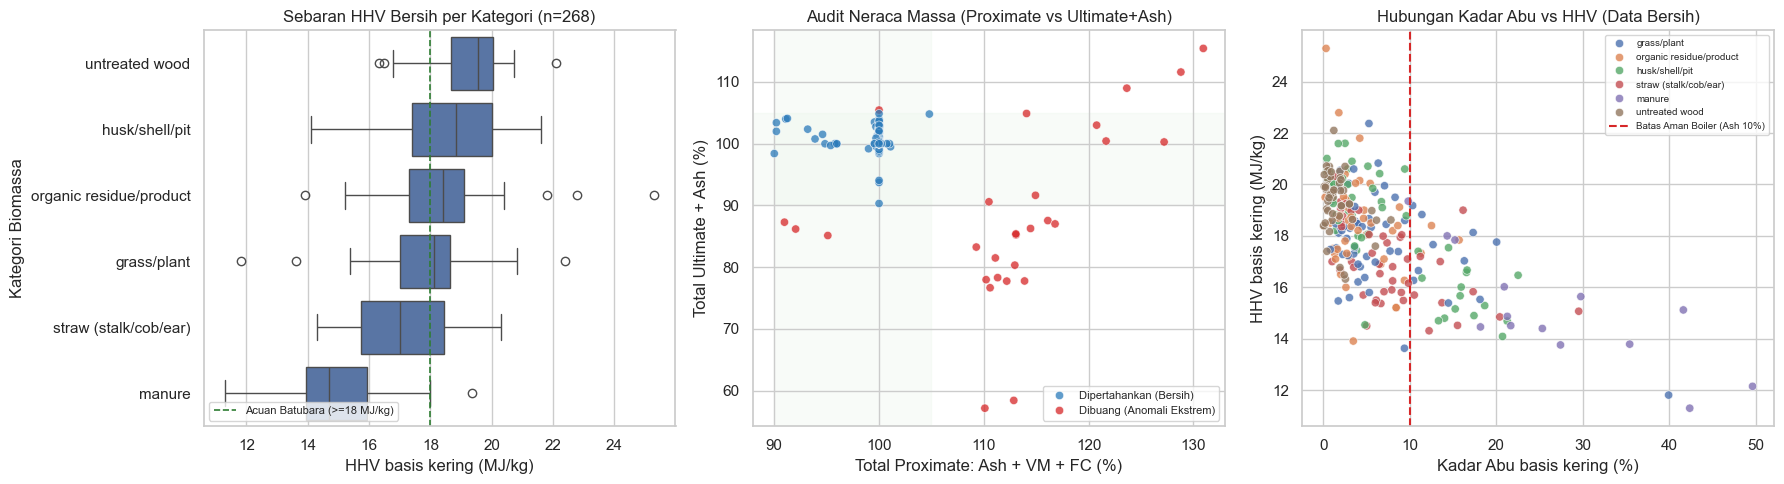

Grafik disimpan ke: D:\UPN VY\Semester 5\BI\Tugas\projectkb\outputs\figures\01_eda_mendeley_overview.png


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

order_cat = df_m_clean.groupby("feedstock_category")["hhv_db"].median().sort_values(ascending=False).index
sns.boxplot(data=df_m_clean, y="feedstock_category", x="hhv_db", order=order_cat, ax=axes[0], color="#4C72B0")
axes[0].axvline(18.0, color="#2E7D32", linestyle="--", linewidth=1.2, label="Acuan Batubara (>=18 MJ/kg)")
axes[0].set_title("Sebaran HHV Bersih per Kategori (n=268)")
axes[0].set_xlabel("HHV basis kering (MJ/kg)")
axes[0].set_ylabel("Kategori Biomassa")
axes[0].legend(loc="lower left", fontsize=8)

df_m_dedup_plot = df_m_dedup.copy()
df_m_dedup_plot["status"] = np.where(extreme_mask, "Dibuang (Anomali Ekstrem)", "Dipertahankan (Bersih)")
sns.scatterplot(
    data=df_m_dedup_plot,
    x="prox_sum",
    y="ult_sum",
    hue="status",
    palette={"Dipertahankan (Bersih)": "#2B7BBA", "Dibuang (Anomali Ekstrem)": "#D62728"},
    alpha=0.75,
    ax=axes[1],
)
axes[1].axvspan(90, 105, color="#E8F5E9", alpha=0.3, zorder=0)
axes[1].axhspan(90, 105, color="#E8F5E9", alpha=0.3, zorder=0)
axes[1].set_title("Audit Neraca Massa (Proximate vs Ultimate+Ash)")
axes[1].set_xlabel("Total Proximate: Ash + VM + FC (%)")
axes[1].set_ylabel("Total Ultimate + Ash (%)")
axes[1].legend(fontsize=8)

sns.scatterplot(
    data=df_m_clean,
    x="ash_db",
    y="hhv_db",
    hue="feedstock_category",
    alpha=0.8,
    ax=axes[2],
)
axes[2].axvline(10.0, color="#D62728", linestyle="--", linewidth=1.5, label="Batas Aman Boiler (Ash 10%)")
axes[2].set_title("Hubungan Kadar Abu vs HHV (Data Bersih)")
axes[2].set_xlabel("Kadar Abu basis kering (%)")
axes[2].set_ylabel("HHV basis kering (MJ/kg)")
axes[2].legend(fontsize=7, loc="upper right")

plt.tight_layout()
mendeley_fig_path = FIGURES_DIR / "01_eda_mendeley_overview.png"
plt.savefig(mendeley_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {mendeley_fig_path}")

**Cara membaca grafik EDA Mendeley:**
- **Panel kiri:** Kelompok `untreated wood` dan `husk/shell/pit` memiliki nilai kalor tertinggi dan paling dekat dengan rentang batu bara kalori rendah-menengah (18-22 MJ/kg), sedangkan `manure` cenderung lebih rendah dan bervariasi lebar.
- **Panel tengah:** Kelompok titik merah dari referensi `[26]` berada jauh di atas 105% pada sumbu Proximate (109%-131%) serta titik dengan Ultimate di bawah 90%. Penyaringan menjaga sebaran bersih terpusat di sekitar titik ideal (100%, 100%).
- **Panel kanan:** Terlihat korelasi negatif antara kadar abu (`ash_db`) dan nilai kalor (`hhv_db`). Garis merah 10% memisahkan kandidat berkadar abu rendah yang layak untuk *co-firing* langsung dari biomassa berkadar abu tinggi.

## 3. Kurasi & Pembersihan 10 Profil Phyllis2 + Parameter RPR

**Langkah yang dikerjakan:**
1. Menyaring `phyllis2_all_18_wide-v3.csv` ke 10 profil biomassa pertanian, perkebunan, dan kayu (`FS01`-`FS10`), serta mengeluarkan `FS11`-`FS18` (`RDF`, `MSW`, `paper`, `plastic`, `untreated wood`, `sugarcane`, `maize`, `cardboard`) yang tidak berpasangan dengan data pasokan maupun `ref_rpr_parameters.csv`.
2. Menyeragamkan nama 8 fitur kimia basis kering (`ash_db` sampai `s_db`) agar identik dengan data latih Mendeley.
3. Mengimputasi `vm_db` dan `fc_db` yang kosong pada `FS01` (`palm kernel shell`) menggunakan rasio rata-rata $\text{VM}/(\text{VM}+\text{FC})$ dari seluruh sampel *Palm kernel shell* di `mendeley_clean.csv`, lalu menskalakannya ke fraksi non-abu `FS01` ($100\% - \text{ash\_db}$) sehingga neraca massa *Proximate* genap 100%.
4. Menstandarisasi Klorin (`cl_db_pct = Cl_dry_mg_kg / 10000`) serta logam alkali (`k_db_pct` dan `na_db_pct`): memakai nilai langsung `mg/kg` jika tersedia (`direct_dry_mg_kg`), atau mengonversi dari komposisi oksida abu `K2O_ash_pct` dan `Na2O_ash_pct` (`estimated_from_ash_oxide`) menggunakan faktor stoikiometri molar ($2\text{K}/\text{K}_2\text{O} = 0{,}83015$ dan $2\text{Na}/\text{Na}_2\text{O} = 0{,}74186$).
5. Menggabungkan seluruh parameter dari `ref_rpr_parameters.csv` (`komoditas_bps`, RPR, `recoverability_factor`, dan `moisture_lapangan_pct`) melalui kunci `feedstock_id`.

In [4]:
phyllis_raw = pd.read_csv(RAW_COMP_DIR / "phyllis2_all_18_wide-v3.csv")
rpr_raw = pd.read_csv(RAW_COMP_DIR / "ref_rpr_parameters.csv")

target_ids = [f"FS{i:02d}" for i in range(1, 11)]
df_p = phyllis_raw.loc[phyllis_raw["feedstock_id"].isin(target_ids)].copy()

rename_phyllis = {
    "Ash_dry_pct": "ash_db",
    "VM_dry_pct": "vm_db",
    "FC_dry_pct": "fc_db",
    "C_dry_pct": "c_db",
    "H_dry_pct": "h_db",
    "O_dry_pct": "o_db",
    "N_dry_pct": "n_db",
    "S_dry_pct": "s_db",
    "HHV_dry_MJ_kg": "actual_hhv_db",
    "LHV_dry_MJ_kg": "actual_lhv_db",
    "Moisture_ar_pct": "moisture_lab_ar_pct",
    "HHV_ar_MJ_kg": "actual_hhv_ar",
    "LHV_ar_MJ_kg": "actual_lhv_ar",
}
df_p = df_p.rename(columns=rename_phyllis)

pks_mendeley = df_m_clean.loc[
    df_m_clean["material"].str.lower().str.contains("palm kernel shell", na=False)
]
assert len(pks_mendeley) >= 1, "Sampel Palm kernel shell tidak ditemukan di mendeley_clean.csv"

pks_vm_mean = pks_mendeley["vm_db"].mean()
pks_fc_mean = pks_mendeley["fc_db"].mean()
vm_share_of_organic = pks_vm_mean / (pks_vm_mean + pks_fc_mean)

fs01_mask = df_p["feedstock_id"] == "FS01"
assert df_p.loc[fs01_mask, "vm_db"].isna().all() and df_p.loc[fs01_mask, "fc_db"].isna().all()

fs01_non_ash = 100.0 - df_p.loc[fs01_mask, "ash_db"].values[0]
df_p.loc[fs01_mask, "vm_db"] = round(fs01_non_ash * vm_share_of_organic, 4)
df_p.loc[fs01_mask, "fc_db"] = round(fs01_non_ash * (1.0 - vm_share_of_organic), 4)
df_p["proximate_source"] = np.where(fs01_mask, "imputed_mendeley_pks_ratio", "phyllis2_measured")

print(
    f"Imputasi FS01 dari {len(pks_mendeley)} sampel PKS Mendeley "
    f"(rasio VM/(VM+FC) = {vm_share_of_organic:.4f}): "
    f"ash_db={df_p.loc[fs01_mask, 'ash_db'].values[0]:.4f}%, "
    f"vm_db={df_p.loc[fs01_mask, 'vm_db'].values[0]:.4f}%, "
    f"fc_db={df_p.loc[fs01_mask, 'fc_db'].values[0]:.4f}%"
)

df_p["cl_db_pct"] = df_p["Cl_dry_mg_kg"] / 10000.0
df_p["cl_source"] = np.where(df_p["cl_db_pct"].notna(), "direct_dry_mg_kg", "unavailable")

K_OXIDE_TO_ELEMENT = 0.83015
NA_OXIDE_TO_ELEMENT = 0.74186

k_list, na_list, alkali_src_list = [], [], []
for _, row in df_p.iterrows():
    if pd.notna(row["K_dry_mg_kg"]) and pd.notna(row["Na_dry_mg_kg"]):
        k_val = row["K_dry_mg_kg"] / 10000.0
        na_val = row["Na_dry_mg_kg"] / 10000.0
        src = "direct_dry_mg_kg"
    elif pd.notna(row["K2O_ash_pct"]) and pd.notna(row["Na2O_ash_pct"]):
        k_val = row["ash_db"] * (row["K2O_ash_pct"] / 100.0) * K_OXIDE_TO_ELEMENT
        na_val = row["ash_db"] * (row["Na2O_ash_pct"] / 100.0) * NA_OXIDE_TO_ELEMENT
        src = "estimated_from_ash_oxide"
    else:
        k_val = np.nan
        na_val = np.nan
        src = "unavailable"
    k_list.append(k_val)
    na_list.append(na_val)
    alkali_src_list.append(src)

df_p["k_db_pct"] = np.round(k_list, 5)
df_p["na_db_pct"] = np.round(na_list, 5)
df_p["alkali_total_db_pct"] = df_p["k_db_pct"] + df_p["na_db_pct"]
df_p["alkali_source"] = alkali_src_list

assert set(df_p["feedstock_id"]) == set(rpr_raw["feedstock_id"]), "Ketidakcocokan feedstock_id Phyllis2 vs RPR"
rpr_cols_to_merge = [
    "feedstock_id", "feedstock_name", "komoditas_bps",
    "basis_produk_primer", "rpr_primer",
    "basis_alternatif_bps", "rpr_alternatif_bps",
    "recoverability_factor", "moisture_lapangan_pct", "referensi_utama",
]
df_p_merged = df_p.merge(
    rpr_raw[rpr_cols_to_merge],
    on="feedstock_id",
    how="left",
    suffixes=("", "_rpr"),
)
assert (df_p_merged["feedstock_name"] == df_p_merged["feedstock_name_rpr"]).all()
df_p_merged = df_p_merged.drop(columns=["feedstock_name_rpr"])

df_p_merged.to_csv(PROCESSED_DIR / "phyllis2_10_clean.csv", index=False)

cols_preview = [
    "feedstock_id", "feedstock_name", "komoditas_bps",
    "ash_db", "vm_db", "fc_db", "s_db", "actual_hhv_db",
    "moisture_lab_ar_pct", "moisture_lapangan_pct",
    "cl_db_pct", "alkali_total_db_pct", "proximate_source", "cl_source", "alkali_source",
]
display(df_p_merged[cols_preview].round(4))

Imputasi FS01 dari 4 sampel PKS Mendeley (rasio VM/(VM+FC) = 0.7810): ash_db=3.9150%, vm_db=75.0444%, fc_db=21.0406%


,feedstock_id,feedstock_name,komoditas_bps,ash_db,vm_db,fc_db,s_db,actual_hhv_db,moisture_lab_ar_pct,moisture_lapangan_pct,cl_db_pct,alkali_total_db_pct,proximate_source,cl_source,alkali_source
0,FS01,palm kernel shell,Kelapa Sawit,3.9150,75.0444,21.0406,0.0275,19.8450,5.3500,12.0,NaN,NaN,imputed_mendeley_pks_ratio,unavailable,unavailable
1,FS02,empty fruit bunches,Kelapa Sawit,4.1825,78.4800,17.8267,0.0680,19.0014,9.6743,55.0,0.2833,0.9354,phyllis2_measured,direct_dry_mg_kg,direct_dry_mg_kg
2,FS03,palm fiber,Kelapa Sawit,4.7867,59.5500,33.6000,0.1600,19.8440,18.3333,40.0,NaN,0.3860,phyllis2_measured,unavailable,estimated_from_ash_oxide
3,FS04,rice husk,Padi,18.0300,62.2000,18.3800,0.1440,14.7088,8.3000,12.0,0.0961,0.3093,phyllis2_measured,direct_dry_mg_kg,direct_dry_mg_kg
4,FS05,rice straw,Padi,18.5254,65.2020,18.0300,0.1250,15.4150,7.4878,15.0,0.5372,1.6250,phyllis2_measured,direct_dry_mg_kg,direct_dry_mg_kg
5,FS06,bagasse,Tebu,5.7910,78.5573,15.5980,0.0969,18.0500,19.0153,50.0,0.1150,0.5579,phyllis2_measured,direct_dry_mg_kg,direct_dry_mg_kg
6,FS07,corn cob,Jagung,2.3657,79.4900,17.8167,0.0767,17.1000,7.5200,12.0,0.2100,0.0609,phyllis2_measured,direct_dry_mg_kg,estimated_from_ash_oxide
7,FS08,corn stover,Jagung,6.0986,78.0433,15.9600,0.0767,18.1375,5.5300,15.0,0.2887,1.0533,phyllis2_measured,direct_dry_mg_kg,estimated_from_ash_oxide
8,FS09,sawdust,Kayu,1.0986,81.9772,17.0578,0.0336,19.9629,15.1026,20.0,0.0367,0.0483,phyllis2_measured,direct_dry_mg_kg,direct_dry_mg_kg
9,FS10,wood chips,Kayu,1.9417,75.7000,17.4000,0.0277,20.3522,22.9450,25.0,0.0125,0.2092,phyllis2_measured,direct_dry_mg_kg,estimated_from_ash_oxide


**Interpretasi hasil kurasi Phyllis2 + RPR (`phyllis2_10_clean.csv`):**
- Seluruh **10 profil (`FS01`-`FS10`)** lengkap pada ke-8 fitur regresi ML tanpa nilai `NaN`.
- `FS01` (`palm kernel shell`) memperoleh `vm_db = 75,04%` dan `fc_db = 21,04%` dengan neraca proksimat tepat 100,0%, dan ditandai `proximate_source = "imputed_mendeley_pks_ratio"` agar pada Notebook 03 dapat dilaporkan evaluasi eksternal baik untuk 10 profil penuh maupun 9 profil terukur murni.
- Nilai `moisture_lapangan_pct` jauh lebih tinggi dari `moisture_lab_ar_pct` pada limbah basah lapangan seperti **TKKS/EFB (`FS02`: 55% vs 9,67%)** dan **ampas tebu/`bagasse` (`FS06`: 50% vs 19,02%)**, sehingga pemakaian kadar air lapangan sangat menentukan realisme kalkulasi LHV pada tahap berikutnya.

## 4. Pembersihan Data Produksi BDSP Kementan (`kabkota`) & Strategi Dual-View

**Langkah yang dikerjakan:** Membaca seluruh **152 file CSV** dari subfolder `kabkota/` pada keempat komoditas BDSP Kementan (`padi`, `jagung`, `kelapa_sawit`, `tebu`), lalu menjalankan empat tahap pembersihan utama:
1. **Harmonisasi 541 kode wilayah mentah menjadi 514 kabupaten/kota resmi (38 provinsi):** Memetakan 26 kode lama pemekaran 4 provinsi baru Papua (`91` Papua Barat ke `92` Papua Barat Daya; `94` Papua ke `95` Papua Selatan, `96` Papua Tengah, dan `97` Papua Pegunungan) ke kode 38-provinsi terbaru serta memetakan 1 kode nama lama `9437` (`Kab. Yapen Waropen`, memiliki 1 entri `3.280,09 ton` Padi 2017 saat `9408` bernilai `0`) ke `9408` (`Kab. Kepulauan Yapen`, nama resmi pasca-PP No. 40/2008) setelah memastikan nol kasus penghitungan ganda pada tahun yang sama.
2. **Standarisasi nama wilayah dan pengeksporan dimensi lokasi (`bdsp_dim_kabkota.csv`):** Memperbaiki kesalahan spasi/titik (`Kab.Nabire`, `Kota. Sorong`, `Kab.Mamberamo Raya`, `Kab. Peg. Bintang`) agar siap menjadi `Dim_Location` di Tahap 3.
3. **Audit anomali ekstrem dan kekosongan pelaporan massal (tanpa imputasi):**
   - Kolom `2026` (seluruhnya `0.0`, belum rilis) dikeluarkan sehingga rentang data bersih adalah `2010-2025`.
   - Anomali skala `Kelapa Sawit` tahun `2015` di `Kab. Tanjung Jabung Barat` (`1507`, Jambi) sebesar `37.959.700 ton` (~100x nilai tahun sekitar ~318-373 ribu ton) diubah menjadi `NaN` dan dicatat di `production_audit_log.csv`.
   - Kekosongan pelaporan massal BDSP yang tertulis `0.0` diubah menjadi `NaN` agar grafik tren tidak jatuh ke nol secara keliru: seluruh 514 kab/kota `Jagung` pada `2023-2025` dan seluruh 23 kab/kota Provinsi Aceh pada `Kelapa Sawit` tahun `2025` (turun dari 508.134 ton di 2024 menjadi nol menyeluruh).
4. **Penyematan metadata `cakupan_data` dan penanda Strategi Dual-View:**
   - `is_anchor_2022`: `True` pada tahun `2022` untuk seluruh komoditas (komparasi satu tahun kalender yang sama).
   - `is_latest_complete_year`: `True` pada tahun penuh terbaik terbaru masing-masing komoditas (`Padi = 2025`, `Kelapa Sawit = 2024` [lingkup PR, mencakup Aceh], `Tebu = 2022` [penuh PR+PBS+PBN], `Jagung = 2017` [penuh nasional 29 provinsi]).
   - `is_latest_available_year`: `True` pada tahun non-kosong paling mutakhir (`Padi = 2025`, `Kelapa Sawit = 2025`, `Tebu = 2025`, `Jagung = 2022`).

**Alasan teknis & acuan Project Brief:**
- Granularitas kab/kota jauh lebih sesuai dengan radius ekonomi pasok biomassa **50-100 km** [CREA 2025] dibanding agregat provinsi.
- Sesuai **Project Brief Bagian 4**, data wilayah yang kosong atau rusak tidak diimputasi dengan angka perkiraan sendiri, melainkan dipertahankan sebagai `NaN` dan didokumentasikan di log audit.

In [5]:
# Pemetaan 26 kode lama pemekaran 4 provinsi Papua -> kode 38-provinsi kanonik
PAPUA_LEGACY_TO_CANONICAL = {
    # 6 kab/kota Papua Barat (91) -> Papua Barat Daya (92)
    9106: 9203,  # Kab. Sorong Selatan
    9107: 9202,  # Kab. Sorong
    9108: 9201,  # Kab. Raja Ampat
    9109: 9205,  # Kab. Tambrauw
    9110: 9204,  # Kab. Maybrat
    9171: 9271,  # Kota Sorong
    # 4 kab/kota Papua (94) -> Papua Selatan (95)
    9401: 9501,  # Kab. Merauke
    9413: 9502,  # Kab. Boven Digoel
    9414: 9503,  # Kab. Mappi
    9415: 9504,  # Kab. Asmat
    # 8 kab/kota Papua (94) -> Papua Tengah (96)
    9404: 9604,  # Kab. Nabire
    9410: 9605,  # Kab. Paniai
    9411: 9608,  # Kab. Puncak Jaya
    9412: 9601,  # Kab. Mimika
    9433: 9607,  # Kab. Puncak
    9434: 9602,  # Kab. Dogiyai
    9435: 9606,  # Kab. Intan Jaya
    9436: 9603,  # Kab. Deiyai
    # 8 kab/kota Papua (94) -> Papua Pegunungan (97)
    9402: 9702,  # Kab. Jayawijaya
    9416: 9707,  # Kab. Yahukimo
    9417: 9708,  # Kab. Pegunungan Bintang
    9418: 9704,  # Kab. Tolikara
    9429: 9701,  # Kab. Nduga
    9430: 9703,  # Kab. Lanny Jaya
    9431: 9705,  # Kab. Mamberamo Tengah
    9432: 9706,  # Kab. Yalimo
    # 1 kode nama lama Papua (94): Kab. Yapen Waropen -> Kab. Kepulauan Yapen (PP No. 40/2008)
    9437: 9408,  # Hanya terisi 3.280,09 ton Padi 2017 saat 9408 bernilai 0; nol di semua tahun/komoditas lain
}

BDSP_SPECS = [
    ("padi", "Padi", "Ton Gabah (GKG)"),
    ("jagung", "Jagung", "Ton Pipilan Kering"),
    ("kelapa_sawit", "Kelapa Sawit", "Ton CPO (OER 22%)"),
    ("tebu", "Tebu", "Ton Gula (Rendemen 7.5%)"),
]
VALID_YEARS = [str(y) for y in range(2010, 2026)]  # 2010-2025 (2026 dibuang karena 100% 0.0)

def clean_kabkota_name(name: str) -> str:
    s = str(name).strip()
    s = re.sub(r"^(Kab|Kota)\.\s*", r"\1. ", s)
    s = re.sub(r"^Kota\.\s*", "Kota ", s)  # Standarkan 'Kota. Sorong' -> 'Kota Sorong'
    s = re.sub(r"\s+", " ", s)
    return s

def classify_cakupan(komoditas: str, tahun: int) -> str:
    if komoditas == "Padi":
        return "PENUH_PRA_KSA" if tahun <= 2017 else "PENUH_KSA"
    if komoditas == "Kelapa Sawit":
        if tahun <= 2017:
            return "PENUH_PR_PBS_PBN"
        return "PR_SAJA" if tahun <= 2024 else "PR_SAJA_TANPA_ACEH"
    if komoditas == "Tebu":
        if tahun == 2010:
            return "PARSIAL_AWAL"
        return "PENUH_PR_PBS_PBN" if tahun <= 2022 else "PARSIAL_PASCA_2022"
    if komoditas == "Jagung":
        if tahun <= 2017:
            return "PENUH"
        if tahun <= 2019:
            return "PARSIAL_TRANSISI"
        return "PARSIAL_9_PROV" if tahun <= 2022 else "TIDAK_TERSEDIA"
    raise ValueError(f"Komoditas tidak dikenal: {komoditas}")

LATEST_COMPLETE_YEAR_MAP = {
    "Padi": 2025,
    "Kelapa Sawit": 2024,
    "Tebu": 2022,
    "Jagung": 2017,
}
LATEST_AVAILABLE_YEAR_MAP = {
    "Padi": 2025,
    "Kelapa Sawit": 2025,
    "Tebu": 2025,
    "Jagung": 2022,
}

audit_records = []
bdsp_long_frames = []
dim_kabkota_df = None

for folder, kom_std, basis_prod in BDSP_SPECS:
    csv_files = sorted(glob.glob(str(RAW_BDSP_DIR / folder / "kabkota" / "*.csv")))
    assert len(csv_files) == 38, f"Harusnya 38 file provinsi di {folder}/kabkota, ditemukan {len(csv_files)}"
    df_raw = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)

    # Pastikan tidak ada nilai negatif dan kolom 2026 memang seluruhnya 0
    assert (df_raw[VALID_YEARS] < 0).sum().sum() == 0, f"Ditemukan nilai negatif di {folder}"
    assert float(df_raw["2026"].sum()) == 0.0, f"Kolom 2026 di {folder} tidak nol!"

    # Verifikasi 0 double-counting pada seluruh 27 pasangan kode lama Papua (26 DOB + 9437->9408) di 2010-2025
    by_code = df_raw.set_index("kode_kabkota")[VALID_YEARS]
    double_cnt = 0
    for old_c, new_c in PAPUA_LEGACY_TO_CANONICAL.items():
        both_pos = (by_code.loc[old_c] > 0) & (by_code.loc[new_c] > 0)
        double_cnt += int(both_pos.sum())
    assert double_cnt == 0, f"Terdeteksi {double_cnt} kasus double counting kode lama Papua pada {folder}!"

    if folder == "padi":
        val_9437 = float(by_code.loc[9437].sum())
        audit_records.append({
            "sumber": "BDSP_KABKOTA",
            "komoditas_bps": "Padi",
            "kode_wilayah": 9437,
            "nama_wilayah": "Kab. Yapen Waropen -> Kab. Kepulauan Yapen (9408)",
            "level_wilayah": "KABKOTA",
            "tahun": "2017",
            "nilai_mentah": val_9437,
            "tindakan": "mapped_legacy_to_canonical_38prov",
            "kategori_audit": "harmonisasi_nama_lama_papua",
            "keterangan": "Kab. Yapen Waropen berganti nama menjadi Kab. Kepulauan Yapen (PP No. 40/2008); entri Padi 2017 (3.280,09 ton) dipetakan ke 9408 tanpa double counting",
        })

    # Bangun tabel referensi dimensi 514 kab/kota kanonik (dari iterasi pertama karena 541 kode identik di 4 komoditas)
    df_canon_meta = df_raw.loc[
        ~df_raw["kode_kabkota"].isin(set(PAPUA_LEGACY_TO_CANONICAL.keys())),
        ["kode_kabkota", "kabupaten_kota", "kode_prov", "provinsi", "pulau"],
    ].copy()
    df_canon_meta["kabupaten_kota"] = df_canon_meta["kabupaten_kota"].map(clean_kabkota_name)
    df_canon_meta["provinsi"] = df_canon_meta["provinsi"].astype(str).str.strip()
    df_canon_meta["pulau"] = df_canon_meta["pulau"].astype(str).str.strip()
    df_canon_meta["is_dob_papua_mapped"] = df_canon_meta["kode_kabkota"].isin(set(PAPUA_LEGACY_TO_CANONICAL.values()))
    df_canon_meta = df_canon_meta.sort_values("kode_kabkota").reset_index(drop=True)
    assert len(df_canon_meta) == 514, f"Harusnya 514 kab/kota kanonik, didapat {len(df_canon_meta)}"
    if dim_kabkota_df is None:
        dim_kabkota_df = df_canon_meta.copy()

    # Petakan 27 kode lama Papua (26 DOB + 9437->9408) ke kode kanonik 38 provinsi, lalu agregasi per (kode_kabkota, tahun)
    df_work = df_raw.copy()
    df_work["kode_kabkota_kanonik"] = df_work["kode_kabkota"].replace(PAPUA_LEGACY_TO_CANONICAL)

    # Ubah wide (2010-2025) -> long
    df_melted = df_work.melt(
        id_vars=["kode_kabkota_kanonik"],
        value_vars=VALID_YEARS,
        var_name="tahun",
        value_name="produksi_ton",
    )
    df_melted["tahun"] = df_melted["tahun"].astype(int)
    df_melted["produksi_ton"] = pd.to_numeric(df_melted["produksi_ton"], errors="coerce")

    # Jumlahkan per kode kanonik (aman karena 0 double-positive pada 26 pasangan Papua)
    df_agg = (
        df_melted.groupby(["kode_kabkota_kanonik", "tahun"], as_index=False)["produksi_ton"]
        .sum()
        .rename(columns={"kode_kabkota_kanonik": "kode_kabkota"})
    )
    df_agg = df_agg.merge(dim_kabkota_df, on="kode_kabkota", how="left")
    df_agg["komoditas_bps"] = kom_std
    df_agg["basis_produk"] = basis_prod
    df_agg["satuan_asli"] = "Ton"
    df_agg["sumber_data"] = "BDSP_KEMENTAN_KABKOTA"

    # Terapkan penanganan anomali ekstrem & kekosongan pelaporan massal -> NaN (tanpa imputasi)
    if kom_std == "Kelapa Sawit":
        # 1) Anomali skala 2015 Kab. Tanjung Jabung Barat (1507): 37.959.700 ton
        anom_mask = (df_agg["kode_kabkota"] == 1507) & (df_agg["tahun"] == 2015)
        raw_val = float(df_agg.loc[anom_mask, "produksi_ton"].values[0])
        assert raw_val > 30_000_000, f"Nilai anomali 1507 tidak sesuai dugaan: {raw_val}"
        df_agg.loc[anom_mask, "produksi_ton"] = np.nan
        audit_records.append({
            "sumber": "BDSP_KABKOTA",
            "komoditas_bps": "Kelapa Sawit",
            "kode_wilayah": 1507,
            "nama_wilayah": "Kab. Tanjung Jabung Barat (Jambi)",
            "level_wilayah": "KABKOTA",
            "tahun": "2015",
            "nilai_mentah": raw_val,
            "tindakan": "set_to_nan_no_imputation",
            "kategori_audit": "anomali_ekstrem_skala",
            "keterangan": "Nilai 37,96 juta ton melampaui total CPO nasional 2015 (31,07 juta ton) dan ~100x nilai tahun sekitar (318-373 ribu ton); diubah ke NaN tanpa imputasi",
        })

        # 2) Kekosongan Provinsi Aceh tahun 2025 (23 kab/kota seluruhnya 0.0 setelah 508.134 ton di 2024)
        aceh_2025_mask = (df_agg["kode_prov"] == 11) & (df_agg["tahun"] == 2025)
        assert float(df_agg.loc[aceh_2025_mask, "produksi_ton"].sum()) == 0.0
        df_agg.loc[aceh_2025_mask, "produksi_ton"] = np.nan
        audit_records.append({
            "sumber": "BDSP_KABKOTA",
            "komoditas_bps": "Kelapa Sawit",
            "kode_wilayah": 11,
            "nama_wilayah": "Aceh (23 kab/kota)",
            "level_wilayah": "PROVINSI_KABKOTA",
            "tahun": "2025",
            "nilai_mentah": 0.0,
            "tindakan": "set_to_nan_no_imputation",
            "kategori_audit": "data_provinsi_kosong_2025",
            "keterangan": "Seluruh 23 kab/kota Aceh bernilai 0 pada 2025 padahal 2024 sebesar 508.134 ton; diubah ke NaN sehingga tahun lengkap terbaru sawit dikunci di 2024",
        })

    if kom_std == "Jagung":
        # Kekosongan nasional BDSP Jagung kab/kota pada 2023, 2024, 2025 (100% 0.0 di seluruh 514 kab/kota)
        for yr_empty in [2023, 2024, 2025]:
            empty_mask = df_agg["tahun"] == yr_empty
            assert float(df_agg.loc[empty_mask, "produksi_ton"].sum()) == 0.0
            df_agg.loc[empty_mask, "produksi_ton"] = np.nan
            audit_records.append({
                "sumber": "BDSP_KABKOTA",
                "komoditas_bps": "Jagung",
                "kode_wilayah": 0,
                "nama_wilayah": "NASIONAL (514 kab/kota)",
                "level_wilayah": "KABKOTA_ALL",
                "tahun": str(yr_empty),
                "nilai_mentah": 0.0,
                "tindakan": "set_to_nan_no_imputation",
                "kategori_audit": "data_bdsp_belum_tersedia",
                "keterangan": f"Seluruh 514 kab/kota Jagung bernilai 0 pada {yr_empty} di BDSP; diubah ke NaN agar tidak terhitung nol aktual pada tren maupun agregasi",
            })

    # Sematkan metadata cakupan & penanda Strategi Dual-View
    df_agg["cakupan_data"] = [classify_cakupan(kom_std, y) for y in df_agg["tahun"]]
    df_agg["is_anchor_2022"] = df_agg["tahun"] == 2022
    df_agg["is_latest_complete_year"] = df_agg["tahun"] == LATEST_COMPLETE_YEAR_MAP[kom_std]
    df_agg["is_latest_available_year"] = df_agg["tahun"] == LATEST_AVAILABLE_YEAR_MAP[kom_std]

    bdsp_long_frames.append(df_agg)

# Catat ringkasan harmonisasi 26 pasangan Papua di audit log
audit_records.append({
    "sumber": "BDSP_KABKOTA",
    "komoditas_bps": "SEMUA_4_KOMODITAS",
    "kode_wilayah": 9194,
    "nama_wilayah": "26 Kab/Kota Pemekaran 4 DOB Papua (91->92, 94->95/96/97)",
    "level_wilayah": "KABKOTA",
    "tahun": "2010-2025",
    "nilai_mentah": np.nan,
    "tindakan": "mapped_legacy_to_canonical_38prov",
    "kategori_audit": "harmonisasi_pemekaran_papua",
    "keterangan": "26 kode lama Papua dipetakan ke kode 38-provinsi terbaru dengan verifikasi 0 kasus double counting pada tahun yang sama; total kab/kota kanonik = 514",
})

df_bdsp_clean = pd.concat(bdsp_long_frames, ignore_index=True)[[
    "kode_kabkota", "kabupaten_kota", "kode_prov", "provinsi", "pulau",
    "tahun", "komoditas_bps", "produksi_ton", "basis_produk", "satuan_asli",
    "cakupan_data", "is_anchor_2022", "is_latest_complete_year", "is_latest_available_year",
    "sumber_data",
]].sort_values(["komoditas_bps", "tahun", "kode_kabkota"]).reset_index(drop=True)

dim_kabkota_df.to_csv(PROCESSED_DIR / "bdsp_dim_kabkota.csv", index=False)
df_bdsp_clean.to_csv(PROCESSED_DIR / "bdsp_kabkota_clean.csv", index=False)

print(f"Dimensi bdsp_dim_kabkota.csv  : {dim_kabkota_df.shape} ({dim_kabkota_df['kode_prov'].nunique()} provinsi, {dim_kabkota_df['kode_kabkota'].nunique()} kab/kota)")
print(f"Dimensi bdsp_kabkota_clean.csv: {df_bdsp_clean.shape}")

# Ringkasan Dual-View BDSP kab/kota
print("\nRingkasan Dual-View BDSP Kab/Kota (Anchor 2022 vs Latest Complete Year):")
dv_rows = []
for kom in ["Padi", "Kelapa Sawit", "Tebu", "Jagung"]:
    sub_a = df_bdsp_clean[(df_bdsp_clean["komoditas_bps"] == kom) & (df_bdsp_clean["is_anchor_2022"])]
    sub_l = df_bdsp_clean[(df_bdsp_clean["komoditas_bps"] == kom) & (df_bdsp_clean["is_latest_complete_year"])]
    dv_rows.append({
        "Komoditas": kom,
        "Basis Produk": sub_a["basis_produk"].iloc[0],
        "Anchor 2022 (Ton)": round(sub_a["produksi_ton"].sum(), 1),
        "Prov Aktif 2022": int(sub_a.loc[sub_a["produksi_ton"] > 0, "kode_prov"].nunique()),
        "Cakupan 2022": sub_a["cakupan_data"].iloc[0],
        "Tahun Lengkap Terbaru": int(sub_l["tahun"].iloc[0]),
        "Latest Complete (Ton)": round(sub_l["produksi_ton"].sum(), 1),
        "Prov Aktif Latest": int(sub_l.loc[sub_l["produksi_ton"] > 0, "kode_prov"].nunique()),
        "Cakupan Latest": sub_l["cakupan_data"].iloc[0],
    })
display(pd.DataFrame(dv_rows))

Dimensi bdsp_dim_kabkota.csv  : (514, 6) (38 provinsi, 514 kab/kota)
Dimensi bdsp_kabkota_clean.csv: (32896, 15)

Ringkasan Dual-View BDSP Kab/Kota (Anchor 2022 vs Latest Complete Year):


,Komoditas,Basis Produk,Anchor 2022 (Ton),Prov Aktif 2022,Cakupan 2022,Tahun Lengkap Terbaru,Latest Complete (Ton),Prov Aktif Latest,Cakupan Latest
0,Padi,Ton Gabah (GKG),54338410.4,38,PENUH_KSA,2025,60206843.7,38,PENUH_KSA
1,Kelapa Sawit,Ton CPO (OER 22%),16310610.0,28,PR_SAJA,2024,16970694.0,28,PR_SAJA
2,Tebu,Ton Gula (Rendemen 7.5%),2405907.0,12,PENUH_PR_PBS_PBN,2022,2405907.0,12,PENUH_PR_PBS_PBN
3,Jagung,Ton Pipilan Kering,5583971.5,9,PARSIAL_9_PROV,2017,25769782.0,33,PENUH


**Interpretasi hasil pembersihan BDSP `kabkota` & Dual-View:**
- Seluruh **152 file CSV** berhasil dikonsolidasi menjadi **32.896 baris** (`514` kab/kota kanonik x `16` tahun `2010-2025` x `4` komoditas) pada `bdsp_kabkota_clean.csv` beserta tabel master `bdsp_dim_kabkota.csv` (**514 kab/kota di 38 provinsi**) tanpa baris ganda pemekaran Papua.
- Pada tampilan **Anchor 2022 (`is_anchor_2022 = True`)**, keempat komoditas berada dalam tahun kalender yang sama (Padi 54,34 juta ton GKG, Kelapa Sawit 16,31 juta ton CPO lingkup PR, Tebu 2,41 juta ton Gula penuh, dan Jagung 5,58 juta ton Pipilan Kering di 9 provinsi).
- Pada tampilan **Latest Complete Year (`is_latest_complete_year = True`)**, masing-masing komoditas tampil pada tahun penuh terbaiknya: **Padi 2025** (60,21 juta ton, 38 prov), **Kelapa Sawit 2024** (16,97 juta ton CPO PR, 28 prov termasuk Aceh), **Tebu 2022** (2,41 juta ton Gula, 12 prov), dan **Jagung 2017** (25,77 juta ton, 29 prov) sehingga sentra jagung nasional seperti Jawa Timur, Lampung, dan Sulawesi Selatan tetap terwakili di peta potensi.

## 5. Pembersihan Data Produksi Kayu BPS RI (Level Pulau & Nasional)

**Langkah yang dikerjakan:** Membersihkan 8 file CSV kayu bulat dari `raw_data/02_bps/bps_ri/` untuk melengkapi pasokan feedstock kayu (`FS09` *sawdust* dan `FS10` *wood chips*) yang tidak tersedia di BDSP Kementan:
1. **`bps_kayu_pulau_clean.csv` (level pulau):** Sumber `1973_kayu_hph_pulau` (2019-2022, satuan asli `M3`). Memisahkan baris `INDONESIA` (`kode_baris == 6`) ke `bps_kayu_nasional_reference.csv`, mempertahankan 5 wilayah pulau, mengonversi ke estimasi tonase memakai $\rho = 0{,}65\text{ ton/m}^3$ sesuai `ref_rpr_parameters.csv`, dan mempertahankan nilai kosong `JAWA` 2019 sebagai `NaN`.
2. **`bps_kayu_nasional_clean.csv` (level nasional):** Sumber `2512_kayu_jenis_pohon` (2020-2023). Menyaring hanya 12 sub-jenis kayu bulat (`kode_baris` 2-13, satuan `m3`), memisahkan baris total `A. JUMLAH KAYU BULAT (M3)` ke `bps_kayu_nasional_reference.csv` untuk validasi penjumlahan, serta mengeluarkan produk non-kayu-bulat (`B`, `C`, `D`).
3. **Penyematan flag Dual-View yang konsisten dengan BDSP:** `is_anchor_2022 = (tahun == 2022)` untuk kedua tabel kayu, serta `is_latest_complete_year` pada `2022` (level pulau) dan `2023` (level nasional).

In [6]:
def standardize_region_name(series: pd.Series) -> pd.Series:
    return (
        series.astype(str)
        .str.strip()
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )

WOOD_DENSITY_TON_M3 = 0.65  # Mengikuti rho = 0.65 ton/m3 pada ref_rpr_parameters.csv
nat_ref_frames = []

# --- 5.1 Kayu HPH Level Pulau (1973_kayu_hph_pulau: 2019-2022) ---
files_1973 = sorted(glob.glob(str(RAW_BPS_DIR / "1973_kayu_hph_pulau" / "*.csv")))
df_1973 = pd.concat([pd.read_csv(f) for f in files_1973], ignore_index=True)
df_1973["label_baris"] = standardize_region_name(df_1973["label_baris"])

is_ind_1973 = df_1973["kode_baris"] == 6
for _, r in df_1973.loc[is_ind_1973].iterrows():
    nat_ref_frames.append({
        "sumber_kelompok": "kayu_hph_pulau",
        "id_tabel_bps": r["id_tabel_bps"],
        "kode_baris": int(r["kode_baris"]),
        "label_baris": r["label_baris"],
        "tahun": int(r["tahun"]),
        "komoditas_bps": "Kayu",
        "basis_produk": "m3 Kayu Bulat (rho 0.65)",
        "nilai_asli": r["nilai"],
        "satuan_asli": r["satuan_asli"],
        "produksi_ton_ekuivalen": r["nilai"] * WOOD_DENSITY_TON_M3,
        "produksi_m3": r["nilai"],
    })

df_bps_kayu_pulau = df_1973.loc[~is_ind_1973, ["kode_baris", "label_baris", "tahun", "nilai", "id_tabel_bps", "satuan_asli"]].copy()
df_bps_kayu_pulau = df_bps_kayu_pulau.rename(columns={
    "kode_baris": "kode_pulau",
    "label_baris": "pulau",
    "nilai": "produksi_m3",
})
df_bps_kayu_pulau["komoditas_bps"] = "Kayu"
df_bps_kayu_pulau["basis_produk"] = "m3 Kayu Bulat (rho 0.65)"
df_bps_kayu_pulau["produksi_ton_est"] = df_bps_kayu_pulau["produksi_m3"] * WOOD_DENSITY_TON_M3
df_bps_kayu_pulau["sumber_segmen_kayu"] = "HPH_Hutan_Alam"
df_bps_kayu_pulau["cakupan_data"] = "HPH_HUTAN_ALAM"
df_bps_kayu_pulau["is_anchor_2022"] = df_bps_kayu_pulau["tahun"] == 2022
df_bps_kayu_pulau["is_latest_complete_year"] = df_bps_kayu_pulau["tahun"] == 2022
df_bps_kayu_pulau["is_latest_available_year"] = df_bps_kayu_pulau["tahun"] == 2022
df_bps_kayu_pulau = df_bps_kayu_pulau.sort_values(["tahun", "kode_pulau"]).reset_index(drop=True)

for _, r in df_bps_kayu_pulau.loc[df_bps_kayu_pulau["produksi_m3"].isna()].iterrows():
    audit_records.append({
        "sumber": "BPS_RI_1973",
        "komoditas_bps": "Kayu",
        "kode_wilayah": int(r["kode_pulau"]),
        "nama_wilayah": r["pulau"],
        "level_wilayah": "PULAU",
        "tahun": str(int(r["tahun"])),
        "nilai_mentah": np.nan,
        "tindakan": "kept_nan_no_imputation",
        "kategori_audit": "data_bps_kosong",
        "keterangan": "Nilai produksi kayu bulat HPH Pulau Jawa tahun 2019 kosong pada tabel asli BPS; dipertahankan NaN",
    })

# --- 5.2 Kayu Pembudidaya Level Nasional (2512_kayu_jenis_pohon: 2020-2023) ---
files_2512 = sorted(glob.glob(str(RAW_BPS_DIR / "2512_kayu_jenis_pohon" / "*.csv")))
df_2512 = pd.concat([pd.read_csv(f) for f in files_2512], ignore_index=True)

df_2512_tot = df_2512.loc[df_2512["kode_baris"] == 1].copy()
df_bps_kayu_nasional = df_2512.loc[df_2512["kode_baris"].between(2, 13)].copy()
df_bps_kayu_nasional = df_bps_kayu_nasional.rename(columns={
    "kode_baris": "kode_jenis_pohon",
    "label_baris": "jenis_pohon",
    "nilai": "produksi_m3",
})
df_bps_kayu_nasional["jenis_pohon_clean"] = (
    df_bps_kayu_nasional["jenis_pohon"]
    .str.replace(r"^\d+\.\s*", "", regex=True)
    .str.replace(r"\s*-\s*kayu bulat\s*\(m3\)$", "", regex=True)
    .str.strip()
)
df_bps_kayu_nasional["komoditas_bps"] = "Kayu"
df_bps_kayu_nasional["basis_produk"] = "m3 Kayu Bulat (rho 0.65)"
df_bps_kayu_nasional["produksi_ton_est"] = df_bps_kayu_nasional["produksi_m3"] * WOOD_DENSITY_TON_M3
df_bps_kayu_nasional["sumber_segmen_kayu"] = "HTI_Pembudidaya_Kehutanan"
df_bps_kayu_nasional["cakupan_data"] = "HTI_PEMBUDIDAYA"
df_bps_kayu_nasional["is_anchor_2022"] = df_bps_kayu_nasional["tahun"] == 2022
df_bps_kayu_nasional["is_latest_complete_year"] = df_bps_kayu_nasional["tahun"] == 2023
df_bps_kayu_nasional["is_latest_available_year"] = df_bps_kayu_nasional["tahun"] == 2023
df_bps_kayu_nasional = df_bps_kayu_nasional[[
    "kode_jenis_pohon", "jenis_pohon", "jenis_pohon_clean", "tahun",
    "komoditas_bps", "produksi_m3", "produksi_ton_est", "basis_produk",
    "sumber_segmen_kayu", "cakupan_data",
    "is_anchor_2022", "is_latest_complete_year", "is_latest_available_year",
    "id_tabel_bps",
]].sort_values(["tahun", "kode_jenis_pohon"]).reset_index(drop=True)

for _, r in df_2512_tot.iterrows():
    nat_ref_frames.append({
        "sumber_kelompok": "kayu_hti_nasional",
        "id_tabel_bps": r["id_tabel_bps"],
        "kode_baris": int(r["kode_baris"]),
        "label_baris": r["label_baris"],
        "tahun": int(r["tahun"]),
        "komoditas_bps": "Kayu",
        "basis_produk": "m3 Kayu Bulat (rho 0.65)",
        "nilai_asli": r["nilai"],
        "satuan_asli": "m3",
        "produksi_ton_ekuivalen": r["nilai"] * WOOD_DENSITY_TON_M3,
        "produksi_m3": r["nilai"],
    })

reconcile_2512 = (
    df_bps_kayu_nasional.groupby("tahun")["produksi_m3"]
    .sum()
    .reset_index(name="sum_12_subjenis_m3")
    .merge(df_2512_tot[["tahun", "nilai"]].rename(columns={"nilai": "total_baris_a_m3"}), on="tahun")
)
reconcile_2512["selisih_abs_m3"] = (reconcile_2512["total_baris_a_m3"] - reconcile_2512["sum_12_subjenis_m3"]).abs()
assert (reconcile_2512["selisih_abs_m3"] <= 2.0).all(), "Selisih penjumlahan sub-jenis kayu > 2 m3!"

df_kayu_ref = pd.DataFrame(nat_ref_frames).sort_values(["sumber_kelompok", "tahun"]).reset_index(drop=True)
df_audit_log = pd.DataFrame(audit_records)

df_bps_kayu_pulau.to_csv(PROCESSED_DIR / "bps_kayu_pulau_clean.csv", index=False)
df_bps_kayu_nasional.to_csv(PROCESSED_DIR / "bps_kayu_nasional_clean.csv", index=False)
df_kayu_ref.to_csv(PROCESSED_DIR / "bps_kayu_nasional_reference.csv", index=False)
df_audit_log.to_csv(PROCESSED_DIR / "production_audit_log.csv", index=False)

print("Rekonsiliasi total 12 sub-jenis kayu HTI terhadap baris A. JUMLAH KAYU BULAT (M3):")
display(reconcile_2512)
print("\nIsi production_audit_log.csv (seluruh anomali, harmonisasi, & NaN tanpa imputasi):")
display(df_audit_log[["sumber", "komoditas_bps", "nama_wilayah", "tahun", "kategori_audit", "tindakan"]])

Rekonsiliasi total 12 sub-jenis kayu HTI terhadap baris A. JUMLAH KAYU BULAT (M3):


,tahun,sum_12_subjenis_m3,total_baris_a_m3,selisih_abs_m3
0,2020,46487679.0,46487679.0,0.0
1,2021,47562910.0,47562910.0,0.0
2,2022,49694377.0,49694376.0,1.0
3,2023,53961327.0,53961325.0,2.0



Isi production_audit_log.csv (seluruh anomali, harmonisasi, & NaN tanpa imputasi):


,sumber,komoditas_bps,nama_wilayah,tahun,kategori_audit,tindakan
0,BDSP_KABKOTA,Padi,Kab. Yapen Waropen -> Kab. Kepulauan Yapen (9408),2017,harmonisasi_nama_lama_papua,mapped_legacy_to_canonical_38prov
1,BDSP_KABKOTA,Jagung,NASIONAL (514 kab/kota),2023,data_bdsp_belum_tersedia,set_to_nan_no_imputation
2,BDSP_KABKOTA,Jagung,NASIONAL (514 kab/kota),2024,data_bdsp_belum_tersedia,set_to_nan_no_imputation
3,BDSP_KABKOTA,Jagung,NASIONAL (514 kab/kota),2025,data_bdsp_belum_tersedia,set_to_nan_no_imputation
4,BDSP_KABKOTA,Kelapa Sawit,Kab. Tanjung Jabung Barat (Jambi),2015,anomali_ekstrem_skala,set_to_nan_no_imputation
5,BDSP_KABKOTA,Kelapa Sawit,Aceh (23 kab/kota),2025,data_provinsi_kosong_2025,set_to_nan_no_imputation
6,BDSP_KABKOTA,SEMUA_4_KOMODITAS,"26 Kab/Kota Pemekaran 4 DOB Papua (91->92, 94-...",2010-2025,harmonisasi_pemekaran_papua,mapped_legacy_to_canonical_38prov
7,BPS_RI_1973,Kayu,JAWA,2019,data_bps_kosong,kept_nan_no_imputation


**Interpretasi hasil pembersihan Kayu BPS & Audit Log:**
- Data kayu bulat tersimpan rapi sesuai granularitas aslinya: `bps_kayu_pulau_clean.csv` (**20 baris**, HPH hutan alam 2019-2022 di 5 wilayah pulau) dan `bps_kayu_nasional_clean.csv` (**48 baris**, 12 sub-jenis kayu bulat HTI 2020-2023). Selisih penjumlahan 12 sub-jenis kayu terhadap baris total `A` hanya 0 hingga 2 m3 (faktor pembulatan BPS).
- Seluruh 8 catatan audit pada `production_audit_log.csv` merekam secara transparan pemetaan kode nama lama `9437` (`Kab. Yapen Waropen` ke `9408` `Kab. Kepulauan Yapen`), harmonisasi 26 kab/kota pemekaran Papua, konversi anomali sawit 2015 `Kab. Tanjung Jabung Barat` ke `NaN`, konversi kekosongan pelaporan massal (`Jagung` 2023-2025 & `Kelapa Sawit` Aceh 2025) ke `NaN`, serta kekosongan kayu HPH Pulau Jawa 2019.

### 5.3 Visualisasi EDA Tren BDSP `kabkota`, Perbandingan Dual-View, & Kayu BPS
**Langkah yang dikerjakan:** Memplot (1) tren produksi tahunan 4 komoditas BDSP `kabkota` 2010-2025 lengkap dengan penanda transisi cakupan, (2) perbandingan langsung tampilan **Dual-View** (`Anchor 2022` vs `Latest Complete Year`), serta (3) tren volume kayu bulat BPS HPH vs HTI.  
**Alasan teknis:** Memudahkan seluruh anggota tim memahami visualisasi dampak strategi Dual-View serta melihat alasan mengapa tahun 2022 dipakai sebagai tahun jangkar komparasi lintas komoditas.

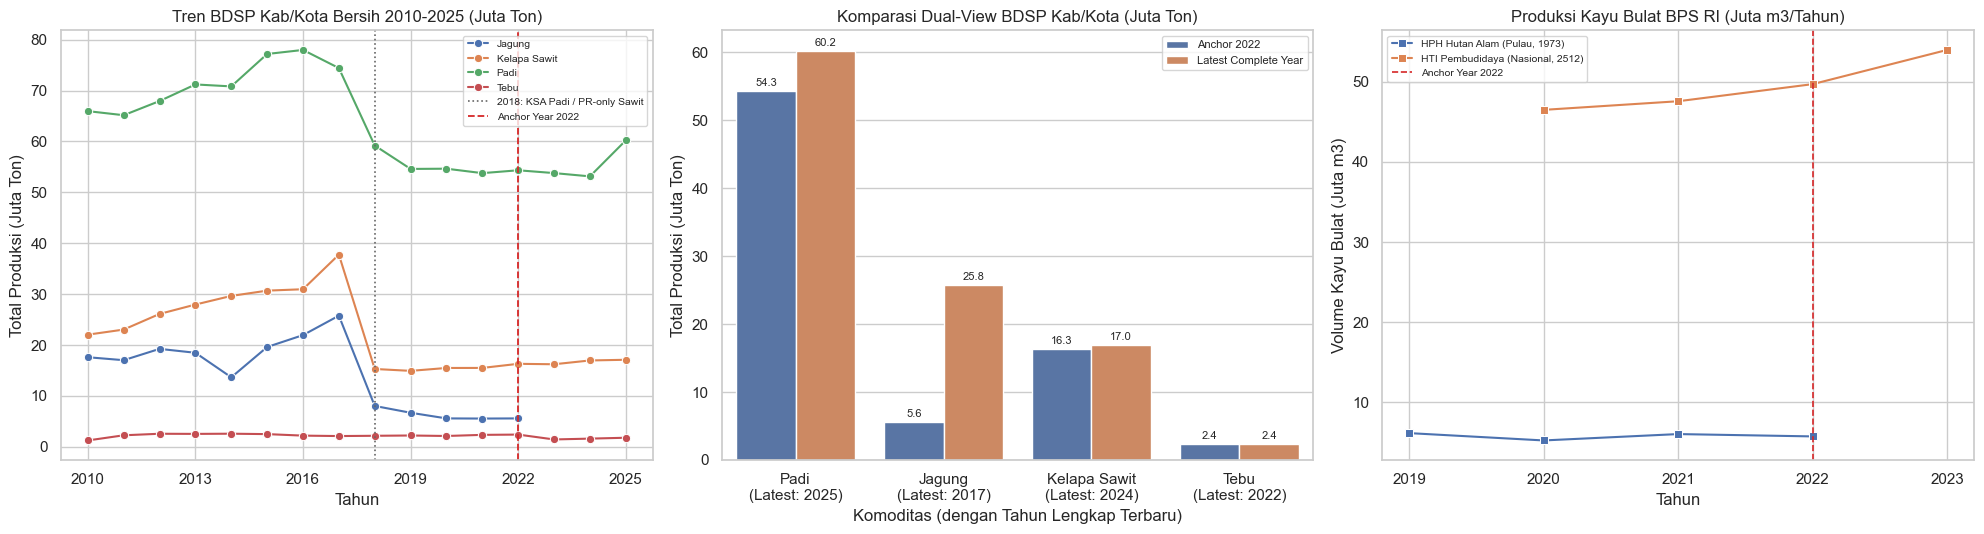

Grafik disimpan ke: D:\UPN VY\Semester 5\BI\Tugas\projectkb\outputs\figures\01_eda_production_dualview.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Panel 1: Tren BDSP Kab/Kota 2010-2025 (Juta Ton)
bdsp_agg = (
    df_bdsp_clean.groupby(["tahun", "komoditas_bps"], as_index=False)["produksi_ton"]
    .sum(min_count=1)
)
bdsp_agg["produksi_juta_ton"] = bdsp_agg["produksi_ton"] / 1e6
sns.lineplot(data=bdsp_agg, x="tahun", y="produksi_juta_ton", hue="komoditas_bps", marker="o", ax=axes[0])
axes[0].axvline(2018, color="#666666", linestyle=":", linewidth=1.2, label="2018: KSA Padi / PR-only Sawit")
axes[0].axvline(2022, color="#D62728", linestyle="--", linewidth=1.3, label="Anchor Year 2022")
axes[0].set_title("Tren BDSP Kab/Kota Bersih 2010-2025 (Juta Ton)")
axes[0].set_xlabel("Tahun")
axes[0].set_ylabel("Total Produksi (Juta Ton)")
axes[0].set_xticks(range(2010, 2026, 3))
axes[0].legend(fontsize=7.5, loc="upper right")

# Panel 2: Perbandingan Dual-View (Anchor 2022 vs Latest Complete Year)
dv_plot_rows = []
for kom in ["Padi", "Jagung", "Kelapa Sawit", "Tebu"]:
    val_a = df_bdsp_clean.loc[(df_bdsp_clean["komoditas_bps"] == kom) & (df_bdsp_clean["is_anchor_2022"]), "produksi_ton"].sum() / 1e6
    sub_l = df_bdsp_clean.loc[(df_bdsp_clean["komoditas_bps"] == kom) & (df_bdsp_clean["is_latest_complete_year"])]
    val_l = sub_l["produksi_ton"].sum() / 1e6
    yr_l = int(sub_l["tahun"].iloc[0])
    dv_plot_rows.append({"Komoditas": f"{kom}\n(Latest: {yr_l})", "Tampilan": "Anchor 2022", "Juta Ton": val_a})
    dv_plot_rows.append({"Komoditas": f"{kom}\n(Latest: {yr_l})", "Tampilan": "Latest Complete Year", "Juta Ton": val_l})

df_dv_plot = pd.DataFrame(dv_plot_rows)
sns.barplot(
    data=df_dv_plot,
    x="Komoditas",
    y="Juta Ton",
    hue="Tampilan",
    palette={"Anchor 2022": "#4C72B0", "Latest Complete Year": "#DD8452"},
    ax=axes[1],
)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f", fontsize=8, padding=2)
axes[1].set_title("Komparasi Dual-View BDSP Kab/Kota (Juta Ton)")
axes[1].set_xlabel("Komoditas (dengan Tahun Lengkap Terbaru)")
axes[1].set_ylabel("Total Produksi (Juta Ton)")
axes[1].legend(fontsize=8)

# Panel 3: Tren Kayu Bulat HPH (Pulau) vs HTI (Nasional)
kayu_hph_agg = df_bps_kayu_pulau.groupby("tahun", as_index=False)["produksi_m3"].sum()
kayu_hph_agg["Segmen"] = "HPH Hutan Alam (Pulau, 1973)"
kayu_hti_agg = df_bps_kayu_nasional.groupby("tahun", as_index=False)["produksi_m3"].sum()
kayu_hti_agg["Segmen"] = "HTI Pembudidaya (Nasional, 2512)"
kayu_all = pd.concat([kayu_hph_agg, kayu_hti_agg], ignore_index=True)
kayu_all["produksi_juta_m3"] = kayu_all["produksi_m3"] / 1e6

sns.lineplot(data=kayu_all, x="tahun", y="produksi_juta_m3", hue="Segmen", marker="s", ax=axes[2])
axes[2].axvline(2022, color="#D62728", linestyle="--", linewidth=1.2, label="Anchor Year 2022")
axes[2].set_xticks(sorted(kayu_all["tahun"].unique()))
axes[2].set_title("Produksi Kayu Bulat BPS RI (Juta m3/Tahun)")
axes[2].set_xlabel("Tahun")
axes[2].set_ylabel("Volume Kayu Bulat (Juta m3)")
axes[2].legend(fontsize=7.5)

plt.tight_layout()
prod_fig_path = FIGURES_DIR / "01_eda_production_dualview.png"
plt.savefig(prod_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Grafik disimpan ke: {prod_fig_path}")

**Cara membaca grafik EDA produksi Dual-View:**
- **Panel kiri:** Garis `Jagung` berhenti bersih pada 2022 (tidak jatuh ke 0 pada 2023-2025 karena sudah dikonversi ke `NaN`), dan lonjakan palsu `Kelapa Sawit` 2015 akibat anomali `Kab. Tanjung Jabung Barat` telah hilang sehingga transisi 2017 ke 2018 (saat cakupan kab/kota beralih ke PR saja) terbaca jujur.
- **Panel tengah:** Memperlihatkan nilai tambah strategi **Dual-View**: pada komoditas `Jagung`, tampilan `Anchor 2022` mencatat 5,6 juta ton (9 provinsi), sedangkan tampilan `Latest Complete Year (2017)` menangkap sebaran penuh nasional sebesar 25,8 juta ton (29 provinsi). Untuk `Padi`, tampilan terbaru memanfaatkan rilis 2025 (60,2 juta ton) dibanding 2022 (54,3 juta ton).
- **Panel kanan:** Volume kayu bulat HTI/pembudidaya (~46-54 juta m3/tahun, tersedia hingga 2023) mendominasi dibanding HPH hutan alam (~5,7-6,3 juta m3/tahun, tersedia hingga 2022), dan keduanya bertemu tepat di tahun jangkar `2022`.

## 6. Verifikasi Otomatis Kelengkapan Tahap 1 & Serah Terima

**Langkah yang dikerjakan:** Menjalankan pemeriksaan otomatis (*assertion*) terhadap seluruh **9 file CSV output** dan **2 grafik EDA** agar seluruh gerbang *Definition of Done* dan *Success Criteria* Tahap 1 terverifikasi sebelum digunakan di Tahap 2 maupun Tahap 3.

In [8]:
expected_csvs = [
    "mendeley_clean.csv",
    "mendeley_cleaning_log.csv",
    "phyllis2_10_clean.csv",
    "bdsp_kabkota_clean.csv",
    "bdsp_dim_kabkota.csv",
    "bps_kayu_pulau_clean.csv",
    "bps_kayu_nasional_clean.csv",
    "bps_kayu_nasional_reference.csv",
    "production_audit_log.csv",
]
expected_figs = [
    "01_eda_mendeley_overview.png",
    "01_eda_production_dualview.png",
]

for fn in expected_csvs:
    p = PROCESSED_DIR / fn
    assert p.exists() and p.stat().st_size > 0, f"Output CSV bermasalah: {p}"
for fn in expected_figs:
    p = FIGURES_DIR / fn
    assert p.exists() and p.stat().st_size > 0, f"Output grafik bermasalah: {p}"

# 1. Verifikasi Mendeley
m_chk = pd.read_csv(PROCESSED_DIR / "mendeley_clean.csv")
m_log_chk = pd.read_csv(PROCESSED_DIR / "mendeley_cleaning_log.csv")
assert len(m_chk) == 268
assert len(m_log_chk) == 47
assert int(m_chk["is_daf_normalized"].sum()) == 14
assert m_chk[feature_target_cols].isna().sum().sum() == 0
assert m_chk.duplicated(subset=feature_target_cols).sum() == 0
assert m_chk["feedstock_category"].nunique() == 6

# 2. Verifikasi Phyllis2 + RPR
p_chk = pd.read_csv(PROCESSED_DIR / "phyllis2_10_clean.csv")
assert len(p_chk) == 10
reg_feats = ["ash_db", "vm_db", "fc_db", "c_db", "h_db", "o_db", "n_db", "s_db"]
assert p_chk[reg_feats + ["actual_hhv_db", "rpr_primer", "rpr_alternatif_bps", "recoverability_factor", "moisture_lapangan_pct"]].isna().sum().sum() == 0
fs01_sum = p_chk.loc[p_chk["feedstock_id"] == "FS01", ["ash_db", "vm_db", "fc_db"]].sum(axis=1).values[0]
assert abs(fs01_sum - 100.0) <= 0.05

# 3. Verifikasi BDSP Kab/Kota + Dual-View
dim_chk = pd.read_csv(PROCESSED_DIR / "bdsp_dim_kabkota.csv")
bdsp_chk = pd.read_csv(PROCESSED_DIR / "bdsp_kabkota_clean.csv")
assert len(dim_chk) == 514 and dim_chk["kode_kabkota"].nunique() == 514 and dim_chk["kode_prov"].nunique() == 38
assert len(bdsp_chk) == 514 * 16 * 4, f"Harusnya 32896 baris, didapat {len(bdsp_chk)}"
assert (bdsp_chk["produksi_ton"].dropna() < 0).sum() == 0
assert bdsp_chk["cakupan_data"].isna().sum() == 0
assert pd.isna(bdsp_chk.loc[(bdsp_chk["komoditas_bps"] == "Kelapa Sawit") & (bdsp_chk["kode_kabkota"] == 1507) & (bdsp_chk["tahun"] == 2015), "produksi_ton"].values[0])
assert bdsp_chk.loc[(bdsp_chk["komoditas_bps"] == "Jagung") & (bdsp_chk["tahun"].isin([2023, 2024, 2025])), "produksi_ton"].isna().all()
assert bdsp_chk.loc[(bdsp_chk["komoditas_bps"] == "Kelapa Sawit") & (bdsp_chk["kode_prov"] == 11) & (bdsp_chk["tahun"] == 2025), "produksi_ton"].isna().all()
assert set(bdsp_chk.loc[bdsp_chk["is_anchor_2022"], "tahun"].unique()) == {2022}
assert set(bdsp_chk.loc[bdsp_chk["is_anchor_2022"], "komoditas_bps"].unique()) == {"Padi", "Jagung", "Kelapa Sawit", "Tebu"}
latest_yrs = bdsp_chk.loc[bdsp_chk["is_latest_complete_year"]].groupby("komoditas_bps")["tahun"].unique().to_dict()
assert {k: int(v[0]) for k, v in latest_yrs.items()} == {"Padi": 2025, "Kelapa Sawit": 2024, "Tebu": 2022, "Jagung": 2017}

# 4. Verifikasi Kayu BPS + Dual-View
b_pulau = pd.read_csv(PROCESSED_DIR / "bps_kayu_pulau_clean.csv")
b_nas = pd.read_csv(PROCESSED_DIR / "bps_kayu_nasional_clean.csv")
assert len(b_pulau) == 20 and "INDONESIA" not in set(b_pulau["pulau"])
assert len(b_nas) == 48 and len(b_nas["kode_jenis_pohon"].unique()) == 12
assert set(b_pulau.loc[b_pulau["is_anchor_2022"], "tahun"].unique()) == {2022}
assert set(b_pulau.loc[b_pulau["is_latest_complete_year"], "tahun"].unique()) == {2022}
assert set(b_nas.loc[b_nas["is_anchor_2022"], "tahun"].unique()) == {2022}
assert set(b_nas.loc[b_nas["is_latest_complete_year"], "tahun"].unique()) == {2023}

print("SELURUH GERBANG VERIFIKASI TAHAP 1 LULUS:")
for fn in expected_csvs:
    df_tmp = pd.read_csv(PROCESSED_DIR / fn)
    print(f"  - {fn:32s}: shape={df_tmp.shape}")
print("\nSerah Terima:")
print("  -> Tahap 2A: notebooks/02_ml_hhv_training_and_shap.ipynb (input: data/processed/mendeley_clean.csv)")
print("  -> Tahap 2B: notebooks/03_external_validation_and_screening.ipynb (input: data/processed/phyllis2_10_clean.csv)")
print("  -> Tahap 3 : Kalkulasi energi kab/kota & Star Schema (input: bdsp_kabkota_clean.csv, bdsp_dim_kabkota.csv, bps_kayu_*_clean.csv, phyllis2_10_validated.csv)")

SELURUH GERBANG VERIFIKASI TAHAP 1 LULUS:
  - mendeley_clean.csv              : shape=(268, 19)
  - mendeley_cleaning_log.csv       : shape=(47, 19)
  - phyllis2_10_clean.csv           : shape=(10, 37)


  - bdsp_kabkota_clean.csv          : shape=(32896, 15)
  - bdsp_dim_kabkota.csv            : shape=(514, 6)
  - bps_kayu_pulau_clean.csv        : shape=(20, 14)
  - bps_kayu_nasional_clean.csv     : shape=(48, 14)
  - bps_kayu_nasional_reference.csv : shape=(8, 11)
  - production_audit_log.csv        : shape=(8, 10)

Serah Terima:
  -> Tahap 2A: notebooks/02_ml_hhv_training_and_shap.ipynb (input: data/processed/mendeley_clean.csv)
  -> Tahap 2B: notebooks/03_external_validation_and_screening.ipynb (input: data/processed/phyllis2_10_clean.csv)
  -> Tahap 3 : Kalkulasi energi kab/kota & Star Schema (input: bdsp_kabkota_clean.csv, bdsp_dim_kabkota.csv, bps_kayu_*_clean.csv, phyllis2_10_validated.csv)
